# Pertemuan 10 — Tugas 2: Perbandingan Fitur pada Klasifikasi SMS

Tugas ini membandingkan dua fitur untuk klasifikasi SMS `spam`/`ham` dengan Multinomial Naive Bayes:

1. Model dengan fitur `CountVectorizer` dan `stop_words` diaktifkan.
2. Model dengan fitur `TF-IDF` dan `stop_words` diaktifkan.

Hasil kedua model dibandingkan untuk menentukan fitur terbaik pada dataset `spam.csv`.

Sumber: [Tugas 2](https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js09-klasifikasi/tugas-2).

## 1. Import Library

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

## 2. Preprocessing Data

Data dimuat, kolom kosong dibuang, kolom diganti nama, dan label di-encode (spam = 1, ham = 0).

In [2]:
df = pd.read_csv('spam.csv', encoding='latin-1')
df = df.drop(df.iloc[:, 2:], axis=1)
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

X = df['SMS'].values
y = df['Labels'].values

print(df['Labels'].value_counts())
df.head()

Labels
0    4825
1     747
Name: count, dtype: int64


,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## 3. Split Data

Data dibagi menjadi 80% latih dan 20% uji dengan `random_state` tetap agar perbandingan adil.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y
)
print('Data latih:', X_train.shape[0], '| Data uji:', X_test.shape[0])

Data latih: 4457 | Data uji: 1115


## 4. Model 1 — CountVectorizer dengan stop_words

Fitur dibentuk dengan `CountVectorizer(stop_words='english')` untuk menghapus kata umum bahasa Inggris, lalu model MultinomialNB dilatih dan dievaluasi.

In [4]:
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)

mnb_cv = MultinomialNB().fit(X_train_cv, y_train)
y_pred_cv = mnb_cv.predict(X_test_cv)

print('Akurasi (CountVectorizer + stop_words):', accuracy_score(y_test, y_pred_cv))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_cv))
print('Laporan Klasifikasi:\n', classification_report(y_test, y_pred_cv, target_names=['ham', 'spam']))

Akurasi (CountVectorizer + stop_words): 0.9820627802690582
Confusion Matrix:
 [[960   6]
 [ 14 135]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



## 5. Model 2 — TF-IDF dengan stop_words

Fitur dibentuk dengan `TfidfVectorizer(stop_words='english')`, lalu model MultinomialNB dilatih dan dievaluasi dengan cara yang sama.

In [5]:
tfidf = TfidfVectorizer(stop_words='english')
X_train_tf = tfidf.fit_transform(X_train)
X_test_tf = tfidf.transform(X_test)

mnb_tf = MultinomialNB().fit(X_train_tf, y_train)
y_pred_tf = mnb_tf.predict(X_test_tf)

print('Akurasi (TF-IDF + stop_words):', accuracy_score(y_test, y_pred_tf))
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_tf))
print('Laporan Klasifikasi:\n', classification_report(y_test, y_pred_tf, target_names=['ham', 'spam']))

Akurasi (TF-IDF + stop_words): 0.9730941704035875
Confusion Matrix:
 [[966   0]
 [ 30 119]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.80      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115



## 6. Perbandingan Hasil

Akurasi kedua model dibandingkan dalam tabel dan grafik batang.

                          Model   Akurasi
0  CountVectorizer + stop_words  0.982063
1           TF-IDF + stop_words  0.973094


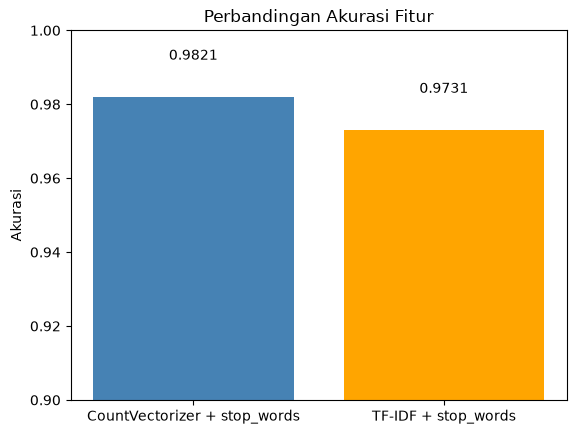

In [6]:
akurasi_cv = accuracy_score(y_test, y_pred_cv)
akurasi_tf = accuracy_score(y_test, y_pred_tf)

hasil = pd.DataFrame({
    'Model': ['CountVectorizer + stop_words', 'TF-IDF + stop_words'],
    'Akurasi': [akurasi_cv, akurasi_tf],
})
print(hasil)

plt.bar(hasil['Model'], hasil['Akurasi'], color=['steelblue', 'orange'])
plt.ylim(0.9, 1.0)
plt.title('Perbandingan Akurasi Fitur')
plt.ylabel('Akurasi')
for i, v in enumerate(hasil['Akurasi']):
    plt.text(i, v + 0.01, f'{v:.4f}', ha='center')
plt.show()

## 7. Kesimpulan Tugas 2

Pada dataset `spam.csv`, kedua fitur menghasilkan akurasi yang tinggi. Fitur yang lebih baik ditentukan dari akurasi, precision, dan recall. Bandingkan hasil keduanya dan jelaskan alasan fitur tersebut lebih baik, misalnya TF-IDF memberi bobot lebih pada kata yang jarang muncul sehingga kata kunci spam lebih menonjol dibanding sekadar menghitung kemunculannya.